# Cartas de control y reglas de Nelson en los rodamientos IMS

**Pregunta.** Una empresa usa 8 reglas de alarma, las reglas de Nelson, sobre cartas de control, y en Superbricks
funcionaron. Este trabajo revisa si esas mismas reglas sirven para anticipar fallas en otra industria, la de máquinas
rotativas, usando rodamientos. Si sirven, también busca con qué tipo de carta funcionan mejor.

**Lo que pidió el profesor**
1. Identificar cuál de las 8 alarmas corresponde a falla.
2. Ver si hay relación en el tiempo entre las alarmas y la falla: si las alarmas aumentan a medida que el rodamiento
   se acerca a fallar. Primero en el ensayo 1 y luego en los ensayos 2 y 3.
3. Para el mismo periodo, además de la carta I-MR, construir las cartas X̄-R y X̄-S y ver con cuál de las tres hay
   mejor relación entre alarma y falla.

**Datos.** Los 3 ensayos del conjunto IMS (Universidad de Cincinnati). En cada ensayo, 4 rodamientos montados en un
mismo eje giran a 2000 revoluciones por minuto, con mucha carga, hasta que uno se daña. Cada 10 minutos se guarda
1 segundo de vibración de cada rodamiento. En total hay 4 rodamientos que fallan y 8 que terminan sanos; los sanos
sirven de control para saber cuántas veces una alarma suena sin que haya falla.

**Cómo está organizado este documento.** Cada sección explica qué se hizo, muestra el resultado, explica en palabras
simples qué quiere decir y termina con el enlace al código que lo calcula. Los cálculos están en scripts de Python
dentro de la carpeta `scripts/` del repositorio; este notebook solo lee sus resultados y los presenta.

### Dónde está el código

Los scripts se corren en este orden. Cada uno lee lo que produjo el anterior y guarda su resultado en un archivo CSV.

| Paso | Script | Qué hace |
| --- | --- | --- |
| 1 | [ims_features.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/ims_features.py) | Lee cada archivo de vibración (1 segundo, 20 480 mediciones) y calcula los indicadores: RMS, curtosis, pico, factor de cresta, energía por bandas de frecuencia y envolvente. |
| 2 | [ims_huecos.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/ims_huecos.py) | Encuentra los huecos en el registro (cuando la prueba se detuvo y se reanudó otro día) y mide cuánto cambió la vibración después de cada reinicio. |
| 3 | [ims_baseline.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/ims_baseline.py) | Elige la línea base de cada ensayo: las 24 horas más estables según el coeficiente de variación. |
| 4 | [ims_subgrupos.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/ims_subgrupos.py) | Parte cada segundo de vibración en 20 trozos para poder construir las cartas X̄-R y X̄-S. |
| 5 | [nelson.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/nelson.py) | Las 8 reglas de Nelson. Se comprobó que dan exactamente lo mismo que la función `reglas_nelson` del código original (Code01). |
| 6 | [ims_cartas.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/ims_cartas.py) | Construye las cartas I-MR, X̄-R y X̄-S para RMS y curtosis, aplica las 8 reglas y guarda cada alarma. |
| 7 | [ims_reglas_falla.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/ims_reglas_falla.py) | Objetivo 1: califica cada alarma y revisa si el resultado puede ser casualidad. |
| 8 | [ims_correlacion.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/ims_correlacion.py) | Objetivo 2: mide si las alarmas aumentan a medida que se acerca la falla y dibuja la figura de la sección 4. |
| 9 | [ims_comparar_cartas.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/ims_comparar_cartas.py) | Objetivo 3: compara las tres cartas con su margen de error. |
| — | [construir_cartas.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/construir_cartas.py) | Genera este notebook. |

Para correrlos se necesita Python con `numpy`, `pandas`, `scipy`, `scikit-learn` y `matplotlib`. Las instrucciones
completas están en el [README del repositorio](https://github.com/mcarocantillo/Mantenimiento-predictivo#cómo-reproducir).

### Términos clave en palabras simples

| Término | Qué es |
| --- | --- |
| RMS | La cantidad promedio de vibración en un segundo. Si sube, el rodamiento vibra más. |
| Curtosis | Mide si la vibración tiene golpes aislados, como los que produce una grieta pequeña cada vez que una bola pasa por ella. |
| Baseline (línea base) | 24 horas en que el rodamiento está sano y estable. De ahí salen el promedio y los límites de lo que se considera normal. |
| σ (sigma) | Cuánto varía normalmente la señal alrededor de su promedio. Un valor a 3σ del promedio es muy raro en una máquina sana. |
| Coeficiente de variación (CV) | σ dividida por el promedio, en porcentaje. Un CV de 1 % quiere decir que la señal casi no cambia. |
| Carta de control | Gráfica de la señal en el tiempo con una línea central (el promedio sano) y límites arriba y abajo. Si la señal se sale de los límites o forma ciertos patrones, suena una alarma. |
| Carta I-MR | Mira cada medición por separado (I) y cuánto cambió respecto a la anterior (MR). Es la que usa el código original. |
| Cartas X̄-R y X̄-S | Agrupan varias mediciones tomadas casi al mismo tiempo; aquí, trozos de 51 milésimas de segundo dentro del mismo segundo. X̄ es el promedio del grupo; R (rango) y S (desviación estándar) miden qué tan distintas son entre sí. R se usa con grupos pequeños (aquí 5) y S con grupos grandes (aquí 20). |
| Alarma de dispersión | La que suena cuando MR, R o S se salen de sus límites, es decir, cuando la señal se vuelve más irregular de lo normal. |
| Falsa alarma | La alarma suena en un rodamiento que está sano. |
| Sensibilidad | De las 48 horas antes de la falla, qué porcentaje del tiempo estuvo sonando la alarma. |
| J de Youden | Una nota para la alarma: sensibilidad menos el porcentaje de tiempo que suena en rodamientos sanos. 1 es perfecta y 0 no sirve. |
| AUC | Probabilidad de que la alarma distinga correctamente un momento previo a la falla de un momento sano. 0,5 es lo mismo que adivinar; 1 es perfecto. |
| Anticipación | Cuántas horas antes de la falla empezó a sonar la alarma de forma sostenida (3 puntos seguidos, es decir, 30 minutos). |
| Valor p | Probabilidad de que un resultado tan bueno salga por pura casualidad. Un p de 0,01 es un 1 %. |

**Las 8 reglas de Nelson**

| Regla | Suena cuando… | Qué suele indicar |
| --- | --- | --- |
| Regla 1 | Un punto queda más allá de 3σ | Un cambio brusco o un valor extremo |
| Regla 2 | 9 puntos seguidos quedan del mismo lado del promedio | El nivel se corrió |
| Regla 3 | 6 puntos seguidos suben (o bajan) | Una tendencia |
| Regla 4 | 14 puntos seguidos alternan arriba y abajo | Una oscilación |
| Regla 5 | 2 de 3 puntos quedan más allá de 2σ, del mismo lado | Un corrimiento moderado |
| Regla 6 | 4 de 5 puntos quedan más allá de 1σ, del mismo lado | Un corrimiento pequeño |
| Regla 7 | 15 puntos seguidos quedan muy cerca del promedio | Variación demasiado baja |
| Regla 8 | 8 puntos seguidos quedan lejos del promedio, a ambos lados | Mezcla de dos situaciones distintas |

In [1]:
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

pd.set_option("display.width", 200, "display.max_columns", 30)

# alarmas_ims.csv es grande (no está en GitHub): si falta, se regenera con el script de la fase 3
if not os.path.exists("alarmas_ims.csv"):
    subprocess.run([sys.executable, "scripts/ims_cartas.py"], check=True)

alarmas = pd.read_csv("alarmas_ims.csv", parse_dates=["Timestamp"])
limites = pd.read_csv("limites_cartas.csv")
base = pd.read_csv("baseline_ims.csv", parse_dates=["base_ini", "base_fin"])
reglas = pd.read_csv("reglas_falla.csv")
correl = pd.read_csv("correlacion_temporal.csv")
comparacion = pd.read_csv("comparacion_cartas.csv")

NOMBRE_VAR = {"rms": "RMS", "kurt": "Curtosis"}
NOMBRE_CARTA = {"I-MR": "I-MR", "Xbar-R": "X̄-R", "Xbar-S": "X̄-S"}
NOMBRE_REGLA = {f"N{i}": f"Regla {i}" for i in range(1, 9)} | {"disp": "Dispersión"}


def etiqueta(v, c, r):
    disp = {"I-MR": "MR", "Xbar-R": "R", "Xbar-S": "S"}[c]
    regla = f"dispersión (carta {disp})" if r == "disp" else NOMBRE_REGLA[r].lower()
    return f"{NOMBRE_VAR[v]} · {NOMBRE_CARTA[c]} · {regla}"


AZUL, NARANJA, ROJO = "#2a78d6", "#eb6834", "#e34948"
TINTA, TINTA2, TENUE, REJILLA, FONDO, GRIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb", "#a9a8a2"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": TENUE, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": REJILLA, "grid.linewidth": 0.6,
    "xtick.color": TENUE, "ytick.color": TENUE, "xtick.labelcolor": TINTA2, "ytick.labelcolor": TINTA2,
    "font.size": 10, "axes.titlesize": 10.5, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.dpi": 110,
})
print(f"{len(alarmas):,} filas de alarmas".replace(",", "."))

227.064 filas de alarmas


## 1. Cómo se ve una carta de control

Antes de los resultados, conviene ver una carta. Aquí está el ensayo 2, que dura 164 horas: **B1 es el rodamiento que
falla** (en la pista externa) y **B2 es uno sano**, montado en el mismo eje.

**Cómo leer estas gráficas**
- El eje horizontal son las horas que faltan para el fin del ensayo. El 0, a la derecha, es el momento de la falla.
- La franja gris de la izquierda es el baseline: las 24 horas sanas con las que se calcularon el promedio y los
  límites.
- La línea continua horizontal es el promedio sano; las líneas punteadas son los límites. Mientras la señal esté
  entre ellas, todo es normal.
- Los puntos rojos son los momentos en que suena la alarma.
- **Columna izquierda:** la carta I-MR del RMS con la regla 1. Es el método original del código.
- **Columna derecha:** la carta S del RMS con su alarma de dispersión. Aquí no se grafica el nivel de vibración, sino
  qué tan distinto es cada trozo de 51 milésimas de segundo de los demás trozos del mismo segundo, comparado con lo
  normal (1 = igual que en el baseline, 2 = el doble de irregular).

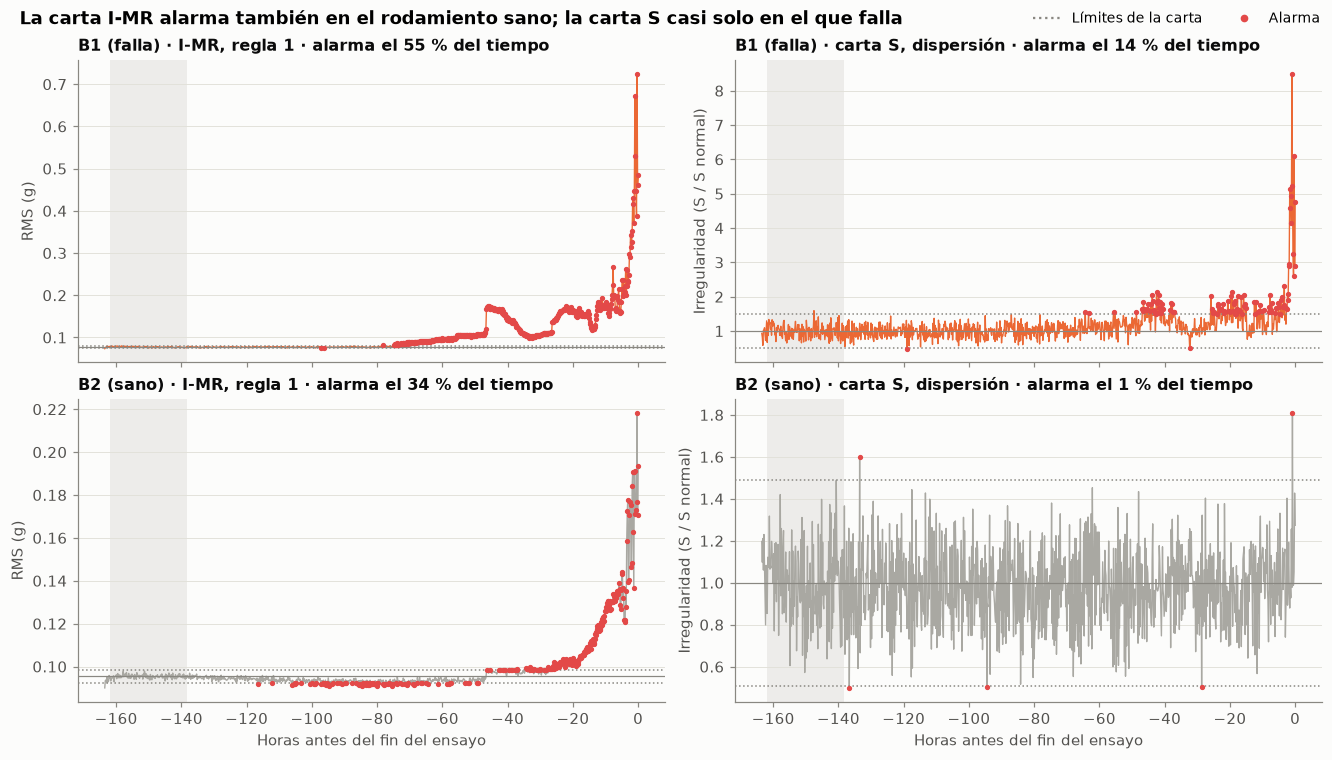

In [2]:
fig, ejes = plt.subplots(2, 2, figsize=(12, 6.8), sharex=True, layout="constrained")
for fila, (rod, estado) in enumerate([("B1", "falla"), ("B2", "sano")]):
    for col, carta in enumerate(["I-MR", "Xbar-S"]):
        ax = ejes[fila, col]
        d = alarmas[(alarmas.ensayo == 2) & (alarmas.rod == rod) & (alarmas["var"] == "rms") & (alarmas.carta == carta)]
        x = -d["horas_al_fin"]
        b = d["fase"] == "base"
        ax.axvspan(x[b].min(), x[b].max(), color=GRIS, alpha=0.18, lw=0)
        color = NARANJA if estado == "falla" else GRIS
        if carta == "I-MR":
            lim = limites[(limites.ensayo == 2) & (limites.rod == rod) & (limites["var"] == "rms") & (limites.carta == carta)].iloc[0]
            y = lim.media + d["z"] * lim.sigma_carta
            ax.plot(x, y, color=color, lw=0.9)
            for k in (-3, 3):
                ax.axhline(lim.media + k * lim.sigma_carta, color=TENUE, ls=":", lw=1)
            ax.axhline(lim.media, color=TENUE, lw=0.8)
            alarma = d["N1"]
            ax.set_ylabel("RMS (g)")
        else:
            y = d["disp_rel"]
            ax.plot(x, y, color=color, lw=0.9)
            for k in (0.510, 1.490):
                ax.axhline(k, color=TENUE, ls=":", lw=1)
            ax.axhline(1, color=TENUE, lw=0.8)
            alarma = d["disp"]
            ax.set_ylabel("Irregularidad (S / S normal)")
        en_alarma = alarma & (d["fase"] == "monitoreo")
        ax.scatter(x[en_alarma], y[en_alarma], s=6, color=ROJO, zorder=3)
        pct = 100 * en_alarma.sum() / (d["fase"] == "monitoreo").sum()
        nombre = "I-MR, regla 1" if carta == "I-MR" else "carta S, dispersión"
        ax.set_title(f"{rod} ({estado}) · {nombre} · alarma el {pct:.0f} % del tiempo", loc="left")
for ax in ejes[1]:
    ax.set_xlabel("Horas antes del fin del ensayo")
fig.legend(handles=[Line2D([], [], color=TENUE, ls=":", label="Límites de la carta"),
                    Line2D([], [], color=ROJO, marker="o", ls="", ms=4, label="Alarma")],
           loc="upper right", ncol=2, fontsize=9)
fig.suptitle("La carta I-MR alarma también en el rodamiento sano; la carta S casi solo en el que falla",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.show()

**Qué quiere decir.**
- En la **carta I-MR** (izquierda), los límites quedan tan pegados al promedio que casi no se ven: la vibración del
  baseline varía apenas un 1 %, así que cualquier cambio pequeño ya se sale. El rodamiento sano (B2, abajo) tiene la
  alarma sonando el 34 % del tiempo. Pasa por dos razones: la vibración de un rodamiento sano baja y sube lentamente
  con los días, y al final del ensayo el rodamiento dañado hace vibrar a todo el eje, incluido el sano.
- En la **carta S** (derecha), el rodamiento sano casi nunca alarma (1 % del tiempo), mientras que en el que falla las
  alarmas se concentran en las últimas 40 horas. La carta S detecta los golpes que produce el daño dentro de cada
  segundo, y esos golpes son propios del rodamiento dañado, no del eje.
- **En la práctica:** con la carta I-MR un técnico recibiría alarmas de los cuatro rodamientos sin saber cuál revisar.
  Con la carta S sabría cuál está fallando.

*Código:* las cartas se construyen en [ims_cartas.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/ims_cartas.py), con las reglas de [nelson.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/nelson.py)
y los subgrupos de [ims_subgrupos.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/ims_subgrupos.py).

## 2. La línea base de cada ensayo

Para dibujar una carta hay que saber qué es "normal". Los límites de todas las cartas se calcularon solo con 24 horas
de funcionamiento sano y estable. Para elegirlas, como en el código original, se usó el coeficiente de variación (CV):
se buscó, en la primera mitad de cada ensayo y sin cruzar ningún reinicio, el bloque de 24 horas en que el CV del RMS
fuera más bajo. Usar solo ese periodo, y no el ensayo completo, evita "hacer trampa" con información del futuro: en
la vida real, cuando se fijan los límites todavía no se sabe qué va a pasar.

In [3]:
rms = base[base["var"] == "rms"]
tabla = rms.groupby("ensayo").agg(inicio=("base_ini", "first"), fin=("base_fin", "first"),
                                  cv_min=("cv_base_%", "min"), cv_max=("cv_base_%", "max"))
tabla["CV del RMS en el baseline"] = [f"{a:.1f} % a {b:.1f} %".replace(".", ",") for a, b in zip(tabla.cv_min, tabla.cv_max)]
tabla = tabla.rename(columns={"inicio": "Inicio", "fin": "Fin"})[["Inicio", "Fin", "CV del RMS en el baseline"]]
tabla.index.name = "Ensayo"
tabla

,Inicio,Fin,CV del RMS en el baseline
Ensayo,,,
1,2003-11-08 10:22:19,2003-11-09 10:05:58,"1,0 % a 1,1 %"
2,2004-02-12 12:02:39,2004-02-13 11:52:39,"0,9 % a 1,8 %"
3,2004-03-19 23:11:57,2004-03-20 23:01:57,"0,9 % a 2,1 %"


**Qué quiere decir.**
- En estos rodamientos, el estado sano tiene un CV de 1 a 2 %: la vibración casi no cambia de un momento a otro.
- En Superbricks se consideraba normal un CV de 10 a 30 %. Aquí esos valores solo aparecen cuando el rodamiento ya
  está fallando (en el EDA se ve que el CV llega a 28–45 % al final).
- **En la práctica:** el umbral de "estado estable" no se puede copiar de una industria a otra; hay que calibrarlo
  para cada tipo de máquina con sus propios datos sanos. Esto es en sí mismo un resultado de la transferencia entre
  industrias.

*Código:* [ims_baseline.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/ims_baseline.py). Los huecos y reinicios se detectan con
[ims_huecos.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/ims_huecos.py).

## 3. Objetivo 1: ¿cuál alarma corresponde a falla?

**Qué se hizo.** Se calcularon 54 alarmas distintas: las 8 reglas de Nelson más la alarma de dispersión (9 alarmas),
en las 3 cartas (I-MR, X̄-R, X̄-S) y para 2 indicadores (RMS y curtosis). A cada una se le puso una nota J:

- Se mira qué porcentaje del tiempo sonó en las 48 horas antes de la falla, en los 4 rodamientos que fallan
  (sensibilidad).
- Se mira qué porcentaje del tiempo sonó en los 8 rodamientos sanos (falsas alarmas).
- La nota J es la resta de las dos. Por ejemplo, una alarma que suena el 60 % del tiempo antes de la falla y el 10 %
  en los sanos tiene J = 0,50.

Cada rodamiento pesa lo mismo, para que el ensayo 3, que es el más largo, no domine el resultado.

**Cómo leer el mapa de colores.** Cada fila es una regla y cada columna una combinación de indicador y carta. Cuanto
más oscuro el azul, mejor la alarma. La celda más oscura es la mejor.

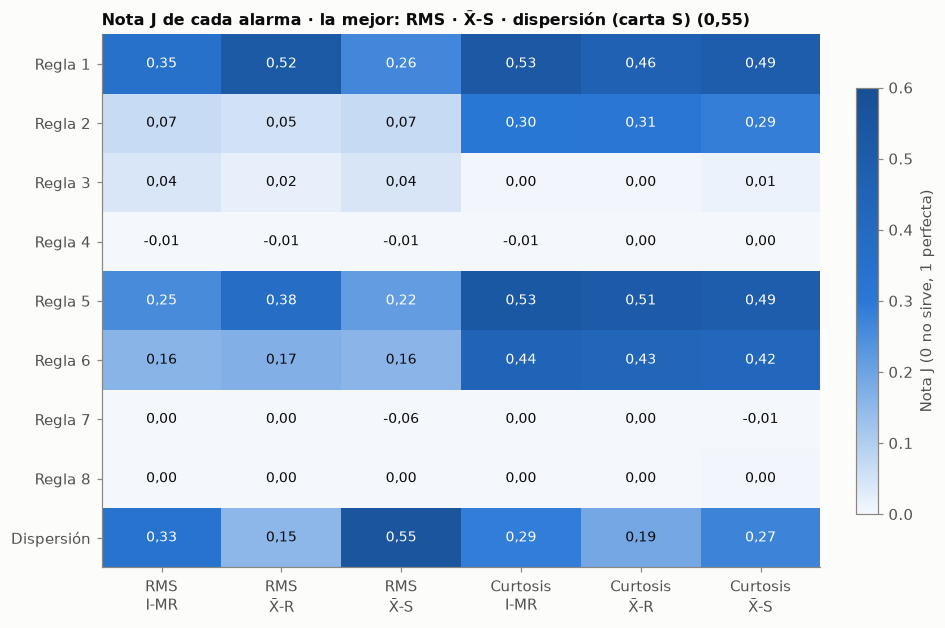

In [4]:
pivote = reglas.assign(col=[f"{NOMBRE_VAR[v]}\n{NOMBRE_CARTA[c]}" for v, c in zip(reglas["var"], reglas.carta)])
pivote = pivote.pivot_table(index="regla", columns="col", values="J_48h")
orden_cols = [f"{NOMBRE_VAR[v]}\n{NOMBRE_CARTA[c]}" for v in ["rms", "kurt"] for c in ["I-MR", "Xbar-R", "Xbar-S"]]
orden_filas = [f"N{i}" for i in range(1, 9)] + ["disp"]
pivote = pivote.loc[orden_filas, orden_cols]

cmap = LinearSegmentedColormap.from_list("azul", ["#f4f8fd", AZUL, "#184f95"])
fig, ax = plt.subplots(figsize=(8.5, 5.6), layout="constrained")
im = ax.imshow(pivote.clip(lower=0), cmap=cmap, vmin=0, vmax=0.6, aspect="auto")
ax.set_xticks(range(len(orden_cols)), orden_cols)
ax.set_yticks(range(len(orden_filas)), [NOMBRE_REGLA[r] for r in orden_filas])
ax.grid(False)
for i in range(len(orden_filas)):
    for j in range(len(orden_cols)):
        v = pivote.iat[i, j]
        ax.text(j, i, f"{v:.2f}".replace(".", ",").replace("-0,00", "0,00"), ha="center", va="center", fontsize=9,
                color="white" if v > 0.2 else TINTA)
fig.colorbar(im, ax=ax, shrink=0.8, label="Nota J (0 no sirve, 1 perfecta)")
mejor = reglas.sort_values("J_48h", ascending=False).iloc[0]
ax.set_title(f"Nota J de cada alarma · la mejor: {etiqueta(mejor['var'], mejor.carta, mejor.regla)} "
             f"({mejor.J_48h:.2f})".replace(".", ",", 1), loc="left")
plt.show()

La tabla siguiente muestra las 5 mejores alarmas y, al final, la del método original para comparar. "Falsas alarmas
por día" cuenta cuántas veces por día, en promedio, la alarma empieza a sonar de forma sostenida (30 minutos
seguidos) en un rodamiento sano.

In [5]:
top = reglas.sort_values("J_48h", ascending=False).head(5)
actual = reglas[(reglas["var"] == "rms") & (reglas.carta == "I-MR") & (reglas.regla == "N1")]
tabla = pd.concat([top, actual]).drop_duplicates(subset=["var", "carta", "regla"])
pd.DataFrame({
    "Alarma": [etiqueta(v, c, r) for v, c, r in zip(tabla["var"], tabla.carta, tabla.regla)],
    "Sonó en las 48 h antes de la falla (%)": tabla["sens_48h_%"].round(0),
    "Sonó en rodamientos sanos (%)": tabla["FPR_sanos_%"].round(0),
    "Falsas alarmas por día": tabla["falsos_eventos_dia"].round(2),
    "Anticipación mediana (h)": tabla["anticip_h_mediana"].round(0),
    "Nota J": tabla["J_48h"].round(2),
}).set_index("Alarma")

,Sonó en las 48 h antes de la falla (%),Sonó en rodamientos sanos (%),Falsas alarmas por día,Anticipación mediana (h),Nota J
Alarma,,,,,
RMS · X̄-S · dispersión (carta S),57.0,2.0,0.07,86.0,0.55
Curtosis · I-MR · regla 5,66.0,13.0,1.47,136.0,0.53
Curtosis · I-MR · regla 1,60.0,7.0,1.10,117.0,0.53
RMS · X̄-R · regla 1,77.0,25.0,2.22,101.0,0.52
Curtosis · X̄-R · regla 5,59.0,9.0,1.31,136.0,0.51
RMS · I-MR · regla 1,84.0,49.0,2.70,112.0,0.35


**Qué quiere decir.**
- La mejor alarma es la de **dispersión de la carta S sobre el RMS**. Suena más de la mitad del tiempo en las 48 horas
  antes de la falla, casi nunca en los sanos (0,07 falsas alarmas por día, es decir, una cada dos semanas) y avisa en
  promedio 86 horas antes, unos 3,5 días.
- Las **reglas 1 y 5 sobre la curtosis** también funcionan y avisan antes (117 a 136 horas), pero dan entre una y una
  vez y media falsa alarma al día. Son útiles como segunda señal, no como alarma principal.
- La **regla 1 sobre el RMS en carta I-MR**, que es el método original, suena el 84 % del tiempo antes de la falla,
  pero también el 49 % del tiempo en rodamientos sanos. En una planta, una alarma así deja de tomarse en serio.
- Las **reglas 3, 4, 7 y 8** tienen nota cercana a 0 en todas las cartas: en rodamientos no se asociaron con la
  falla. Se podrían desactivar para no generar alarmas inútiles.
- **Respuesta al objetivo 1:** las alarmas que corresponden a falla son la de dispersión (con la carta S) y las reglas
  1 y 5 (con la curtosis).

**¿Puede ser casualidad?** Para comprobarlo se hizo una prueba de permutación: se fingió que había fallado otro
rodamiento del mismo ensayo, en las 96 combinaciones posibles, y se recalculó la nota J. Para la mejor alarma, la
combinación real es la que da la nota más alta de las 96, así que la probabilidad de que salga así por casualidad es
de 1 en 96, cerca del 1 % (p = 0,010). Pero
como se probaron 54 alarmas a la vez, alguna podía salir bien por suerte; al corregir por eso (correcciones de Holm y
de Benjamini-Hochberg), el resultado deja de ser concluyente. Con solo 4 fallas no hay datos suficientes para
afirmarlo con fuerza estadística; hay que confirmarlo con otro conjunto de datos.

*Código:* [ims_reglas_falla.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/ims_reglas_falla.py). La tabla completa de las 54 alarmas está en
`reglas_falla.csv`.

## 4. Objetivo 2: ¿las alarmas aumentan cuando se acerca la falla?

**Qué se hizo.** Se contó qué porcentaje del tiempo estuvo sonando cada alarma en bloques de 6 horas, y se midió si
ese porcentaje aumenta a medida que se acerca el fin del ensayo. Se hizo para los 3 ensayos, como pidió el profesor.

**Cómo leer la figura.** Hay tres paneles, uno por alarma. En cada uno:
- El eje horizontal son las horas que faltan para la falla, en la última semana (168 horas).
- La línea naranja es el promedio de los 4 rodamientos que fallan; la azul, el de los 8 sanos. La franja de color
  alrededor de cada línea muestra dónde está la mitad central de los rodamientos.
- Una buena alarma tiene la línea naranja subiendo y la azul plana y abajo.

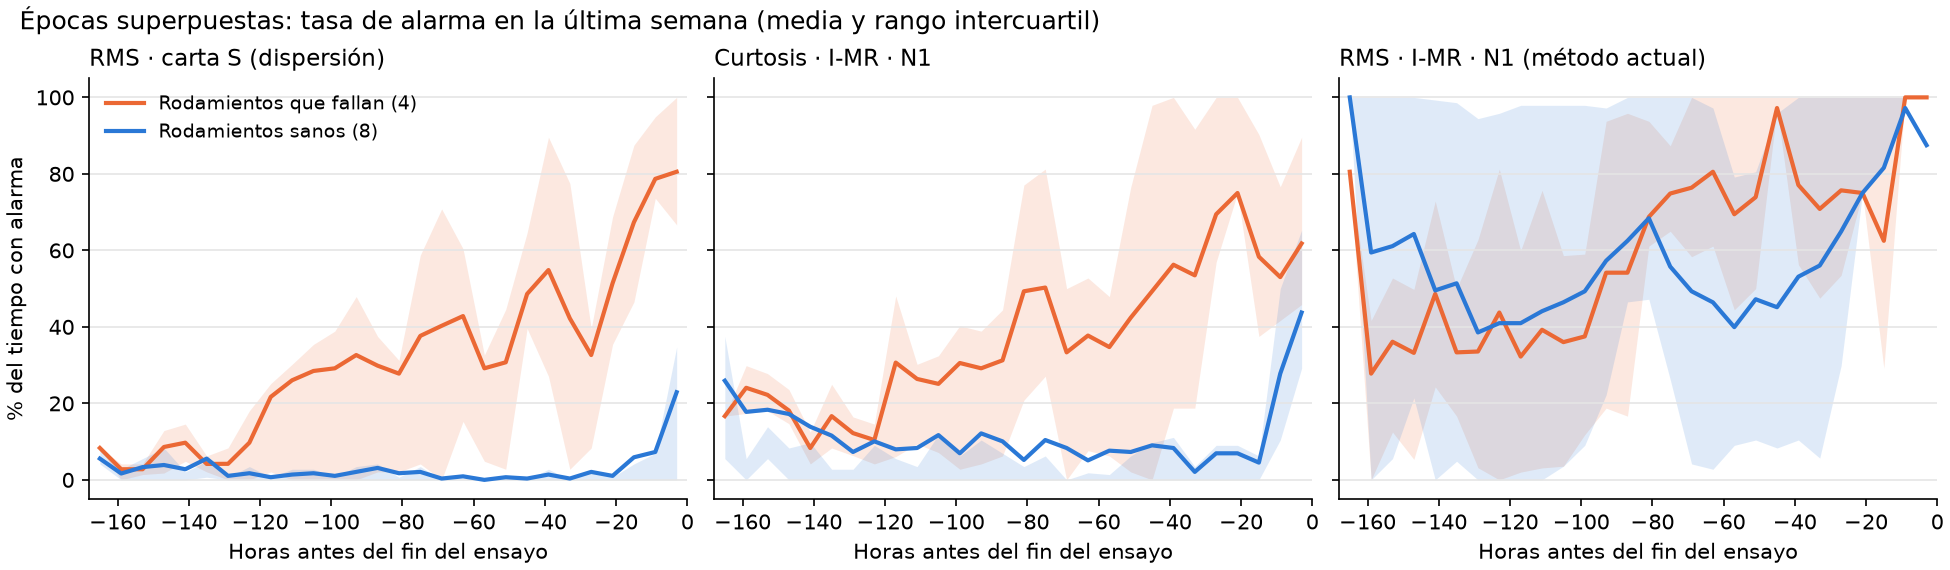

In [6]:
display(Image("fig_epocas.png"))

La tabla resume la figura con un número, la correlación de Spearman (ρ). ρ mide si la alarma suena cada vez más a
medida que pasa el tiempo: 1 quiere decir que siempre aumenta, 0 que no cambia. Una buena alarma tiene ρ alto en los
rodamientos que fallan y bajo en los sanos.

In [7]:
filas = [("rms", "Xbar-S", "disp"), ("kurt", "I-MR", "N1"), ("rms", "I-MR", "N1")]
t = correl.set_index(["var", "carta", "regla"]).loc[filas].reset_index()
pd.DataFrame({
    "Alarma": [etiqueta(v, c, r) for v, c, r in zip(t["var"], t.carta, t.regla)],
    "ρ en los rodamientos que fallan": t.rho_fallan.round(2),
    "ρ en los rodamientos sanos": t.rho_sanos.round(2),
    "Diferencia": t["dif"].round(2),
}).set_index("Alarma")

,ρ en los rodamientos que fallan,ρ en los rodamientos sanos,Diferencia
Alarma,,,
RMS · X̄-S · dispersión (carta S),0.63,0.14,0.49
Curtosis · I-MR · regla 1,0.59,0.31,0.28
RMS · I-MR · regla 1,0.79,0.52,0.26


**Qué quiere decir.**
- Con el **método original** (RMS en I-MR, panel derecho), las alarmas aumentan al acercarse el final tanto en los
  rodamientos que fallan como en los sanos (ρ de 0,79 y 0,52). Sí hay relación en el tiempo, pero no es específica:
  toda la máquina vibra más al final.
- Con la **carta S** (panel izquierdo) y con la **curtosis** (panel central), las alarmas aumentan en el rodamiento
  que falla y casi nada en los sanos. En la figura, la línea naranja se separa de la azul unas 120 horas (5 días)
  antes de la falla y la distancia crece hasta el final.
- **Respuesta al objetivo 2:** sí hay relación en el tiempo entre las alarmas y la falla en los 3 ensayos. Con la
  carta S y la curtosis, además, esa relación apunta al rodamiento correcto.

*Código:* [ims_correlacion.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/ims_correlacion.py), que también genera la figura `fig_epocas.png`.

## 5. Objetivo 3: ¿qué carta funciona mejor?

**Qué se hizo.** Para comparar las cartas sin depender de una regla en particular se usó el AUC. El AUC responde
esta pregunta: si se toma al azar un momento de las 48 horas antes de una falla y un momento de un rodamiento sano,
¿con qué probabilidad la carta le da un valor más alarmante al primero? 0,5 es lo mismo que lanzar una moneda y 1 es
acertar siempre.

Cada carta tiene dos partes, y se evaluaron por separado:
- **Posición:** la parte que mira el nivel de la señal (la carta I o la carta X̄).
- **Dispersión:** la parte que mira qué tan irregular es la señal (MR, R o S).

Entre corchetes está el margen de error, calculado repitiendo el análisis 2000 veces con muestras al azar de los
rodamientos (bootstrap). Si los márgenes de dos cartas se cruzan, no se puede decir que una sea mejor que la otra.

In [8]:
auc = comparacion[comparacion["métrica"] == "AUC"].copy()
auc["Qué mira la carta"] = [f"{NOMBRE_VAR[v]} · " + ("posición" if e == "abs_z" else "dispersión")
                            for v, e in zip(auc["var"], auc["estadístico/regla"])]
auc.set_index("Qué mira la carta")[["I-MR", "Xbar-R", "Xbar-S"]].rename(columns=NOMBRE_CARTA)

,I-MR,X̄-R,X̄-S
Qué mira la carta,,,
RMS · posición,"0.81 [0.64, 0.98]","0.82 [0.65, 0.98]","0.77 [0.55, 0.99]"
RMS · dispersión,"0.73 [0.69, 0.77]","0.69 [0.63, 0.75]","0.86 [0.77, 0.95]"
Curtosis · posición,"0.79 [0.54, 0.97]","0.78 [0.62, 0.93]","0.80 [0.59, 0.96]"
Curtosis · dispersión,"0.68 [0.47, 0.86]","0.61 [0.44, 0.82]","0.61 [0.39, 0.88]"


**Qué quiere decir.**
- Para la **dispersión del RMS**, la carta S es claramente mejor que las otras dos: 0,86 frente a 0,73 de la carta MR
  y 0,69 de la carta R. Su margen de error (0,77 a 0,95) no se cruza con el de las otras, así que la diferencia no es
  casualidad.
- Para la **posición** del RMS y para la **curtosis**, las tres cartas dan resultados parecidos y sus márgenes se
  cruzan: no se puede decir que una gane.
- **Respuesta al objetivo 3:** de las tres cartas, la X̄-S es la que tiene mejor relación entre alarma y falla, gracias
  a su parte S. La X̄-R no mejora a la I-MR.
- **En la práctica:** si se vigila el RMS, conviene usar la carta S en lugar de la I-MR del método original.

*Código:* [ims_comparar_cartas.py](https://github.com/mcarocantillo/Mantenimiento-predictivo/blob/main/scripts/ims_comparar_cartas.py). El detalle con las diferencias entre cartas está en
`comparacion_cartas.csv`.

## 6. Conclusiones

| Lo que pidió el profesor | Respuesta |
| --- | --- |
| 1. ¿Cuál de las 8 alarmas corresponde a falla? | La alarma de dispersión (con la carta S) y las reglas 1 y 5 (con la curtosis). Las reglas 3, 4, 7 y 8 no se asociaron con la falla. |
| 2. ¿Hay relación en el tiempo entre alarmas y falla (ensayos 1, 2 y 3)? | Sí, en los tres ensayos. Con el método original la relación aparece también en los rodamientos sanos; con la carta S y la curtosis, solo en el que falla, desde unas 120 horas antes. |
| 3. ¿Con cuál carta (I-MR, X̄-R, X̄-S) hay mejor relación falla-alarma? | Con la X̄-S, por su parte S: AUC de 0,86 frente a 0,73 de la I-MR. |

**Otros hallazgos importantes**
- El criterio de estabilidad de Superbricks (CV de 10 a 30 %) no se transfiere a rodamientos, donde lo normal es
  cerca de 1 %.
- El método original da muchas falsas alarmas porque el RMS cambia lentamente aunque el rodamiento esté sano, salta
  con los reinicios de la prueba y, al final, todos los rodamientos vibran juntos.
- Con solo 4 fallas, los resultados son consistentes pero no concluyentes desde el punto de vista estadístico. Hay
  que confirmarlos con más datos.

## 7. Qué sigue: Machine Learning para predecir la falla

Con las reglas de Nelson ya evaluadas, el siguiente paso es probar si un modelo de Machine Learning puede avisar
**antes** que la mejor alarma (la carta S), o con menos falsas alarmas. Todo se puede hacer con los datos que ya
tenemos, sin agregar sensores ni modificar el equipo.

**1. Modelos que aprenden solo de lo sano (no supervisados).** Son la primera opción, porque hay muchos datos sanos y
solo 4 fallas. El modelo aprende cómo vibra un rodamiento sano a partir de varios indicadores a la vez (RMS, curtosis,
envolvente, energía por bandas) y avisa cuando algo se aleja de eso. Se probarían Isolation Forest, One-Class SVM,
análisis de componentes principales con la estadística T² de Hotelling y la distancia al grupo sano. La pregunta
clave es si su señal de anomalía sube antes que las alarmas de Nelson, y cuántas horas antes.

**2. Modelos que aprenden de ejemplos (supervisados).** Se entrenaría un modelo para responder "¿va a sonar una alarma
(o a fallar el rodamiento) en las próximas 24 a 48 horas?" a partir de las últimas horas de vibración. Se probarían
regresión logística, k-vecinos más cercanos, máquinas de soporte vectorial, Random Forest y XGBoost. Para que la
prueba sea justa, el modelo se entrena con dos ensayos y se evalúa en el tercero, que nunca vio.

**3. Pronóstico de la señal.** Predecir hacia dónde va el RMS o la curtosis en las próximas horas y avisar cuando el
pronóstico vaya a cruzar los límites de la carta, antes de que la señal real los cruce.

**4. Mejores indicadores de entrada.** Agregar tendencias de las últimas horas (por ejemplo, cuánto subió la curtosis
en el último día), usar los dos sensores del ensayo 1 por separado y medir la envolvente en la frecuencia real del
defecto. Después, ver cuáles indicadores usa más el modelo para anticipar la falla.

**5. Comparación con la mejor alarma de Nelson.** Cada modelo se evaluará con las mismas medidas usadas aquí: horas de
anticipación, falsas alarmas por día, nota J y AUC. También se comparará contra un modelo "tonto" que no aprende nada,
para asegurarse de que el modelo realmente aporta.

**6. Más datos.** Para que los resultados sean concluyentes, repetir lo mejor en otro conjunto público de rodamientos
llevados hasta la falla (FEMTO/PRONOSTIA o XJTU-SY), que tienen más fallas que IMS.

Con 4 fallas en IMS, los modelos muy complejos tienden a memorizar los datos en lugar de aprender el patrón. Por eso
se empezará por los modelos no supervisados y por los supervisados más simples.